## Setup Environment

In [ ]:
# Install specific libraries
! pip install transformers
! pip install -q gradio beautifulsoup4 requests

In [ ]:
import numpy as np
import pandas as pd
import transformers
from transformers import AutoModel, BertTokenizerFast
import matplotlib.pyplot as plt
# from sklearn.metrics import plot_confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
import torch
import torch.nn as nn
# specify GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
# Mount Google Drive - applicable, if working on Google Drive
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Set Working Directory - if working on Google Drive
%cd /content/drive/MyDrive/NTI Final PROJ

# # Set Working Directory - if working on Local Machine
# import os
# os.chdir('/Users//replace_me')

/content/drive/MyDrive/NTI Final PROJ


## Load Dataset

In [ ]:
# Load Dataset
true_data = pd.read_csv('a1_True.csv')
fake_data = pd.read_csv('a2_Fake.csv')

# Generate labels True/Fake under new Target Column in 'true_data' and 'fake_data'
true_data['Target'] = ['True']*len(true_data)
fake_data['Target'] = ['Fake']*len(fake_data)

# Define a dictionary for label mapping
label_map = {"Fake": 1, "True": 0}

# Apply the label mapping to the 'Target' column in both DataFrames
true_data['label'] = true_data['Target'].replace(label_map)
fake_data['label'] = fake_data['Target'].replace(label_map)

# Merge 'true_data' and 'fake_data', by random mixing into a single df called 'data'
data = pd.concat([true_data, fake_data]).sample(frac=1).reset_index(drop=True)


# See how the data looks like
print(data.shape)
data.head()

/tmp/ipykernel_9562/3103075910.py:13: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  true_data['label'] = true_data['Target'].replace(label_map)
/tmp/ipykernel_9562/3103075910.py:14: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  fake_data['label'] = fake_data['Target'].replace(label_map)


(44898, 6)


,title,text,subject,date,Target,label
0,#TREXIT: SWING STATE APOCALYPSE…Democrats LEAV...,Hillary s campaign has been working in coordin...,politics,"Oct 13, 2016",Fake,1
1,White House In Chaos As Trump Fires Scaramucc...,Just ten days into the job and White House com...,News,"July 31, 2017",Fake,1
2,EPIC! CNN ANCHOR DON LEMON Cuts Interview Afte...,,politics,"Feb 18, 2017",Fake,1
3,U.S. urges Myanmar to address rights abuse all...,WASHINGTON (Reuters) - U.S. Secretary of State...,worldnews,"September 19, 2017",True,0
4,China's Xi vows to 'open wider' while defendin...,BEIJING (Reuters) - President Xi Jinping vowed...,worldnews,"November 12, 2017",True,0


In [ ]:
data.head()

,title,text,subject,date,Target,label
0,#TREXIT: SWING STATE APOCALYPSE…Democrats LEAV...,Hillary s campaign has been working in coordin...,politics,"Oct 13, 2016",Fake,1
1,White House In Chaos As Trump Fires Scaramucc...,Just ten days into the job and White House com...,News,"July 31, 2017",Fake,1
2,EPIC! CNN ANCHOR DON LEMON Cuts Interview Afte...,,politics,"Feb 18, 2017",Fake,1
3,U.S. urges Myanmar to address rights abuse all...,WASHINGTON (Reuters) - U.S. Secretary of State...,worldnews,"September 19, 2017",True,0
4,China's Xi vows to 'open wider' while defendin...,BEIJING (Reuters) - President Xi Jinping vowed...,worldnews,"November 12, 2017",True,0


([<matplotlib.patches.Wedge at 0x7bc3719c1be0>,
 [Text(-1.1968726922452788, -0.0865780489358482, 'Fake'),
  Text(1.196872705318187, 0.08657786821309862, 'True')],
 [Text(-0.6981757371430793, -0.05050386187924477, '52.3%'),
  Text(0.6981757447689423, 0.05050375645764086, '47.7%')])

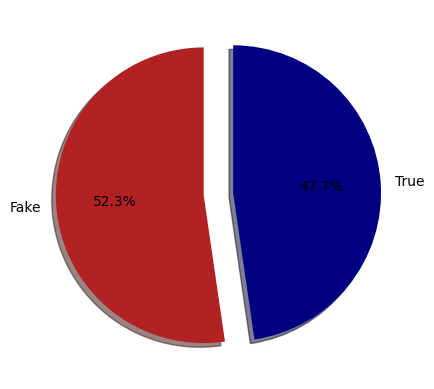

In [ ]:
# Checking if our data is well balanced
label_size = [data['label'].sum(),len(data['label'])-data['label'].sum()]
plt.pie(label_size,explode=[0.1,0.1],colors=['firebrick','navy'],startangle=90,shadow=True,labels=['Fake','True'],autopct='%1.1f%%')

## Train-test-split

In [ ]:
# Train-Validation-Test set split into 70:15:15 ratio
# Train-Temp split
train_text, temp_text, train_labels, temp_labels = train_test_split(data['title'], data['label'],
                                                                    random_state=2018,
                                                                    test_size=0.3,
                                                                    stratify=data['Target'])
# Validation-Test split
val_text, test_text, val_labels, test_labels = train_test_split(temp_text, temp_labels,
                                                                random_state=2018,
                                                                test_size=0.5,
                                                                stratify=temp_labels)

## BERT Fine-tuning

### Load pretrained BERT Model

In [ ]:
# Load BERT model and tokenizer via HuggingFace Transformers
bert = AutoModel.from_pretrained('bert-base-uncased')
tokenizer = BertTokenizerFast.from_pretrained('bert-base-uncased')

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


### Prepare Input Data

Text(0, 0.5, 'Number of texts')

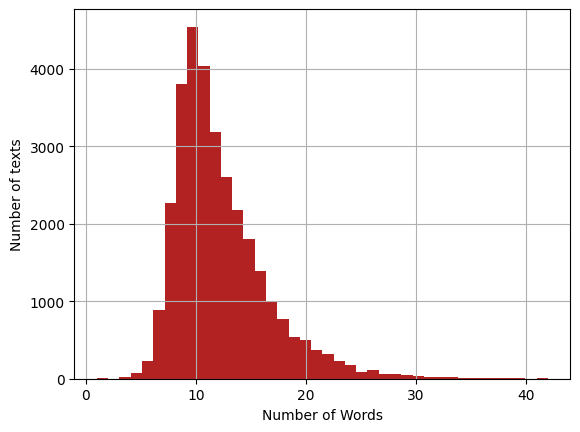

In [ ]:
# Plot histogram of the number of words in train data 'title'
seq_len = [len(title.split()) for title in train_text]

pd.Series(seq_len).hist(bins = 40,color='firebrick')
plt.xlabel('Number of Words')
plt.ylabel('Number of texts')

In [ ]:
# BERT Tokeizer Functionality
sample_data = ["Build fake news model.",
               "Using bert."]                                         # sample data
tokenized_sample_data = tokenizer(sample_data,
                                  padding=True)     # encode text
print(tokenized_sample_data)

# Ref: https://huggingface.co/docs/transformers/preprocessing

{'input_ids': [[101, 3857, 8275, 2739, 2944, 1012, 102], [101, 2478, 14324, 1012, 102, 0, 0]], 'token_type_ids': [[0, 0, 0, 0, 0, 0, 0], [0, 0, 0, 0, 0, 0, 0]], 'attention_mask': [[1, 1, 1, 1, 1, 1, 1], [1, 1, 1, 1, 1, 0, 0]]}


In [ ]:
# Majority of titles above have word length under 15. So, we set max title length as 15
MAX_LENGHT = 15
# Tokenize and encode sequences in the train set
tokens_train = tokenizer(
    train_text.tolist(),
    max_length = MAX_LENGHT,
    padding="max_length",
    truncation=True
)
# tokenize and encode sequences in the validation set
tokens_val = tokenizer(
    val_text.tolist(),
    max_length = MAX_LENGHT,
    padding="max_length",
    truncation=True
)
# tokenize and encode sequences in the test set
tokens_test = tokenizer(
    test_text.tolist(),
    max_length = MAX_LENGHT,
    padding="max_length",
    truncation=True
)

In [ ]:
# Convert lists to tensors
train_seq = torch.tensor(tokens_train['input_ids'])
train_mask = torch.tensor(tokens_train['attention_mask'])
train_y = torch.tensor(train_labels.tolist())

val_seq = torch.tensor(tokens_val['input_ids'])
val_mask = torch.tensor(tokens_val['attention_mask'])
val_y = torch.tensor(val_labels.tolist())

test_seq = torch.tensor(tokens_test['input_ids'])
test_mask = torch.tensor(tokens_test['attention_mask'])
test_y = torch.tensor(test_labels.tolist())

In [ ]:
# Data Loader structure definition
from torch.utils.data import TensorDataset, DataLoader, RandomSampler, SequentialSampler
batch_size = 32                                               #define a batch size

train_data = TensorDataset(train_seq, train_mask, train_y)    # wrap tensors
train_sampler = RandomSampler(train_data)                     # sampler for sampling the data during training
train_dataloader = DataLoader(train_data, sampler=train_sampler, batch_size=batch_size)
                                                              # dataLoader for train set
val_data = TensorDataset(val_seq, val_mask, val_y)            # wrap tensors
val_sampler = SequentialSampler(val_data)                     # sampler for sampling the data during training
val_dataloader = DataLoader(val_data, sampler = val_sampler, batch_size=batch_size)
                                                              # dataLoader for validation set

### Freeze Layers

In [ ]:
# Freezing the parameters and defining trainable BERT structure
for param in bert.parameters():
    param.requires_grad = False    # false here means gradient need not be computed

### Define Model Architecture

In [ ]:
class BERT_Arch(nn.Module):
    def __init__(self, bert):
      super(BERT_Arch, self).__init__()
      self.bert = bert
      self.dropout = nn.Dropout(0.1)            # dropout layer
      self.relu =  nn.ReLU()                    # relu activation function
      self.fc1 = nn.Linear(768,512)             # dense layer 1
      self.fc2 = nn.Linear(512,2)               # dense layer 2 (Output layer)
      self.softmax = nn.LogSoftmax(dim=1)       # softmax activation function
    def forward(self, sent_id, mask):           # define the forward pass
      cls_hs = self.bert(sent_id, attention_mask=mask)['pooler_output']
                                                # pass the inputs to the model
      x = self.fc1(cls_hs)
      x = self.relu(x)
      x = self.dropout(x)
      x = self.fc2(x)                           # output layer
      x = self.softmax(x)                       # apply softmax activation
      return x

model = BERT_Arch(bert)


In [ ]:
# Training setup (only needed if you retrain; not needed for the Gradio app)
# Defining the hyperparameters (optimizer, weights of the classes and the epochs)
# Define the optimizer
from torch.optim import AdamW   # transformers.AdamW was removed in newer versions
optimizer = AdamW(model.parameters(),
                  lr = 1e-5)          # learning rate
# Define the loss function
cross_entropy  = nn.NLLLoss()
# Number of training epochs
epochs = 2

### Define Train & Evaluate Function

In [ ]:
# Defining training and evaluation functions
def train():
  model.train()
  total_loss, total_accuracy = 0, 0

  for step,batch in enumerate(train_dataloader):                # iterate over batches
    if step % 50 == 0 and not step == 0:                        # progress update after every 50 batches.
      print('  Batch {:>5,}  of  {:>5,}.'.format(step, len(train_dataloader)))
    batch = [r for r in batch]                                  # push the batch to gpu
    sent_id, mask, labels = batch
    model.zero_grad()                                           # clear previously calculated gradients
    preds = model(sent_id, mask)                                # get model predictions for current batch
    loss = cross_entropy(preds, labels)                         # compute loss between actual & predicted values
    # loss = torch.nn.functional.nll_loss(preds, labels)           # compute loss using nll_loss (assuming it expects raw logits)
    total_loss = total_loss + loss.item()                       # add on to the total loss
    loss.backward()                                             # backward pass to calculate the gradients
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)     # clip gradients to 1.0. It helps in preventing exploding gradient problem
    optimizer.step()                                            # update parameters
    preds=preds.detach().cpu().numpy()                          # model predictions are stored on GPU. So, push it to CPU

  avg_loss = total_loss / len(train_dataloader)                 # compute training loss of the epoch
                                                                # reshape predictions in form of (# samples, # classes)
  return avg_loss                                 # returns the loss and predictions

def evaluate():
  print("\nEvaluating...")
  model.eval()                                    # Deactivate dropout layers
  total_loss, total_accuracy = 0, 0
  for step,batch in enumerate(val_dataloader):    # Iterate over batches
    if step % 50 == 0 and not step == 0:          # Progress update every 50 batches.
                                                  # Calculate elapsed time in minutes.
                                                  # Elapsed = format_time(time.time() - t0)
      print('  Batch {:>5,}  of  {:>5,}.'.format(step, len(val_dataloader)))
                                                  # Report progress
    batch = [t for t in batch]                    # Push the batch to GPU
    sent_id, mask, labels = batch
    with torch.no_grad():                         # Deactivate autograd
      preds = model(sent_id, mask)                # Model predictions
      loss = cross_entropy(preds,labels)          # Compute the validation loss between actual and predicted values
      total_loss = total_loss + loss.item()
      preds = preds.detach().cpu().numpy()
  avg_loss = total_loss / len(val_dataloader)         # compute the validation loss of the epoch
  return avg_loss

### Model training

In [ ]:
# Deployment guard: stops "Run all" from retraining and overwriting c2_new_model_weights.pt.
# Leave False to skip training. Set to True ONLY if you really want to retrain (training code is unchanged).
RUN_TRAINING = False
print("Training is ON" if RUN_TRAINING else "Training is OFF: the training cell below will do nothing.")

In [ ]:
# Train and predict
best_valid_loss = float('inf')
train_losses=[]                   # empty lists to store training and validation loss of each epoch
valid_losses=[]

for epoch in range(epochs if RUN_TRAINING else 0):   # RUN_TRAINING is set in the cell above
    print('\n Epoch {:} / {:}'.format(epoch + 1, epochs))
    train_loss = train()                       # train model
    valid_loss = evaluate()                    # evaluate model
    if valid_loss < best_valid_loss:              # save the best model
        best_valid_loss = valid_loss
        torch.save(model.state_dict(), 'c2_new_model_weights.pt')
    train_losses.append(train_loss)               # append training and validation loss
    valid_losses.append(valid_loss)

    print(f'\nTraining Loss: {train_loss:.3f}')
    print(f'Validation Loss: {valid_loss:.3f}')


 Epoch 1 / 2
  Batch    50  of    983.
  Batch   100  of    983.
  Batch   150  of    983.
  Batch   200  of    983.
  Batch   250  of    983.
  Batch   300  of    983.
  Batch   350  of    983.
  Batch   400  of    983.
  Batch   450  of    983.
  Batch   500  of    983.
  Batch   550  of    983.
  Batch   600  of    983.
  Batch   650  of    983.
  Batch   700  of    983.
  Batch   750  of    983.
  Batch   800  of    983.
  Batch   850  of    983.
  Batch   900  of    983.
  Batch   950  of    983.

Evaluating...
  Batch    50  of    211.
  Batch   100  of    211.
  Batch   150  of    211.
  Batch   200  of    211.

Training Loss: 0.562
Validation Loss: 0.488

 Epoch 2 / 2
  Batch    50  of    983.
  Batch   100  of    983.
  Batch   150  of    983.
  Batch   200  of    983.
  Batch   250  of    983.
  Batch   300  of    983.
  Batch   350  of    983.
  Batch   400  of    983.
  Batch   450  of    983.
  Batch   500  of    983.
  Batch   550  of    983.
  Batch   600  of    983.
  

### Model performance

In [ ]:
# load weights of best model
# Ensure model is defined
try:
    model
except NameError:
    # Instantiate model using the bert architecture defined in prior cells
    model = BERT_Arch(bert)

path = 'c2_new_model_weights.pt'
model.load_state_dict(torch.load(path, map_location="cpu"))

<All keys matched successfully>

In [ ]:
with torch.no_grad():
  preds = model(test_seq, test_mask)
  preds = preds.detach().cpu().numpy()

preds = np.argmax(preds, axis = 1)
print(classification_report(test_y, preds))

              precision    recall  f1-score   support

           0       0.79      0.90      0.84      3212
           1       0.90      0.79      0.84      3523

    accuracy                           0.84      6735
   macro avg       0.84      0.84      0.84      6735
weighted avg       0.85      0.84      0.84      6735



## Fake News Predictions

In [ ]:
# # load weights of best model
# path = 'c1_fakenews_weights.pt'
# model.load_state_dict(torch.load(path))

In [ ]:
# testing on unseen data
unseen_news_text = ["Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing",     # Fake
                    "WATCH: George W. Bush Calls Out Trump For Supporting White Supremacy",        # Fake
                    "U.S. lawmakers question businessman at 2016 Trump Tower meeting: sources",           # True
                    "Trump administration issues new rules on U.S. visa waivers"                          # True
                    ]

# tokenize and encode sequences in the test set
MAX_LENGHT = 15
tokens_unseen = tokenizer(
    unseen_news_text,
    max_length = MAX_LENGHT,
    padding="max_length",
    truncation=True
)

unseen_seq = torch.tensor(tokens_unseen['input_ids'])
unseen_mask = torch.tensor(tokens_unseen['attention_mask'])

with torch.no_grad():
  preds = model(unseen_seq, unseen_mask)
  preds = preds.detach().cpu().numpy()

preds = np.argmax(preds, axis = 1)
preds

array([1, 0, 0, 0])

## Gradio App (uses the saved weights, no retraining)

**To launch the app without retraining, run only these cells:** the installs, imports, Drive mount and working-directory cells at the top, *Load pretrained BERT*, *Define Model Architecture*, and then every cell in this section. The dataset, split and training cells are not needed.

**Existing results (from the test-set report above, 6,735 headlines):** accuracy 0.83, macro F1 0.83. Real: precision 0.77 / recall 0.92. Fake: precision 0.91 / recall 0.75. These are the saved outputs of the original run and are not recomputed here: the dataset shuffle is unseeded, so a new split would overlap the old training data.

**Important limits:** the model was trained on **headlines only** (first 15 tokens). For a URL the app extracts the page headline and classifies that. The article body is shown as a preview but is not used. Scores are model confidence, not proof that a story is true or false.

In [ ]:
import os
WEIGHTS_PATH = "c2_new_model_weights.pt"      # saved in the project folder set in the %cd cell
if not os.path.exists(WEIGHTS_PATH):
    raise FileNotFoundError(f"{WEIGHTS_PATH} not found in {os.getcwd()}. Check the Drive folder in the %cd cell.")

model.load_state_dict(torch.load(WEIGHTS_PATH, map_location="cpu"))
model.eval()                                   # turn dropout off for inference
print("Weights loaded from", os.path.join(os.getcwd(), WEIGHTS_PATH))

Weights loaded from /content/drive/MyDrive/NTI Final PROJ/c2_new_model_weights.pt


In [ ]:
import re

CLASS_NAMES = ["Real", "Fake"]    # index 0 = True/Real, 1 = Fake (label_map in the data cell: Fake=1, True=0)
MAX_LENGTH = 15                   # same as training

def score_headlines(headlines):
    """Returns an array of [P(Real), P(Fake)] per headline, using the same tokenizer settings as training."""
    # Call the tokenizer directly as a function instead of using batch_encode_plus
    enc = tokenizer(headlines, max_length=MAX_LENGTH, padding="max_length",
                    truncation=True, return_tensors="pt")
    with torch.no_grad():
        log_probs = model(enc["input_ids"], enc["attention_mask"])   # model ends in LogSoftmax
    return torch.exp(log_probs).numpy()

# Loading check: the four headlines from the original notebook (a loading check, not an evaluation)
samples = [("Donald Trump Sends Out Embarrassing New Year’s Eve Message; This is Disturbing", "Fake"),
           ("WATCH: George W. Bush Calls Out Trump For Supporting White Supremacy", "Fake"),
           ("U.S. lawmakers question businessman at 2016 Trump Tower meeting: sources", "Real"),
           ("Trump administration issues new rules on U.S. visa waivers", "Real")]
probs = score_headlines([s for s, _ in samples])
for (s, expected), p in zip(samples, probs):
    print(f"{CLASS_NAMES[int(p.argmax())]:>4}  (Real {p[0]:.1%} | Fake {p[1]:.1%})   expected {expected:>4}   {s[:60]}")

Fake  (Real 25.9% | Fake 74.1%)   expected Fake   Donald Trump Sends Out Embarrassing New Year’s Eve Message; 
Real  (Real 53.3% | Fake 46.7%)   expected Fake   WATCH: George W. Bush Calls Out Trump For Supporting White S
Real  (Real 78.7% | Fake 21.3%)   expected Real   U.S. lawmakers question businessman at 2016 Trump Tower meet
Real  (Real 81.9% | Fake 18.1%)   expected Real   Trump administration issues new rules on U.S. visa waivers


In [ ]:
import socket, ipaddress, requests
from urllib.parse import urlparse, urljoin
from bs4 import BeautifulSoup

TIMEOUT, MAX_BYTES, MAX_REDIRECTS = 10, 2_000_000, 4
HEADERS = {"User-Agent": "Mozilla/5.0 (compatible; FakeNewsDemo/1.0)"}

def looks_like_url(text):
    return bool(re.match(r"^([a-z][a-z0-9+.-]*://|www\.)\S+$", text.strip(), re.I))   # any scheme, so ftp:// etc. get a clear error

def check_url(url):
    """Allow only http/https and block localhost / private / internal addresses."""
    p = urlparse(url)
    if p.scheme not in ("http", "https") or not p.hostname:
        raise ValueError("Please enter a valid http:// or https:// URL.")
    try:
        infos = socket.getaddrinfo(p.hostname, p.port or (443 if p.scheme == "https" else 80))
    except socket.gaierror:
        raise ValueError("Could not find that website. Check the address.")
    for info in infos:
        ip = ipaddress.ip_address(info[4][0])
        if ip.is_private or ip.is_loopback or ip.is_link_local or ip.is_reserved or ip.is_multicast or ip.is_unspecified:
            raise ValueError("That address points to a private or internal network, so it is blocked.")

def fetch_html(url):
    """Download a page, following redirects manually so every destination is re-validated."""
    for _ in range(MAX_REDIRECTS + 1):
        check_url(url)
        r = requests.get(url, headers=HEADERS, timeout=TIMEOUT, stream=True, allow_redirects=False)
        if r.status_code in (301, 302, 303, 307, 308):
            loc = r.headers.get("Location"); r.close()
            if not loc:
                raise ValueError("The site sent a broken redirect.")
            url = urljoin(url, loc)
            continue
        if r.status_code != 200:
            r.close()
            raise ValueError(f"The page returned HTTP {r.status_code}. It may block automated access or need a login. "
                             "You can paste the headline instead.")
        if "html" not in r.headers.get("Content-Type", "").lower():
            r.close()
            raise ValueError("That link is not a web page. You can paste the headline instead.")
        data = b""
        for chunk in r.iter_content(65536):
            data += chunk
            if len(data) > MAX_BYTES:      # keep only the first 2 MB
                break
        r.close()
        return data
    raise ValueError("Too many redirects.")

def clean_headline(t):
    t = re.sub(r"\s+", " ", t).strip()
    return re.sub(r"\s+[-–—|]\s+[^-–—|]{2,30}$", "", t).strip()      # drop a trailing " - Site Name"

def extract_article(url):
    """Returns (headline, body_preview) from a news page."""
    soup = BeautifulSoup(fetch_html(url), "html.parser")
    for tag in soup(["script", "style", "noscript"]):
        tag.decompose()
    headline = ""
    og = soup.find("meta", attrs={"property": "og:title"})
    if og and og.get("content", "").strip():
        headline = og["content"]
    elif soup.find("h1") and soup.find("h1").get_text(strip=True):
        headline = soup.find("h1").get_text(" ", strip=True)
    elif soup.title and soup.title.get_text(strip=True):
        headline = soup.title.get_text(strip=True)
    headline = clean_headline(headline)
    if not headline:
        raise ValueError("Could not find a headline on that page. You can paste it instead.")
    paras = [p.get_text(" ", strip=True) for p in soup.find_all("p")]
    preview = " ".join(p for p in paras if len(p) >= 60)[:600]
    return headline, preview

In [ ]:
MIN_WORDS = 3
DISCLAIMER = ("*Scores are the model's confidence, not proof that a story is true or false. "
              "The model only looks at the headline.*")

def pick_headline(text):
    """The model expects a headline: use the first line (or first sentence if it is a long block)."""
    h = [l.strip() for l in text.splitlines() if l.strip()][0]
    if len(h.split()) > 30:
        h = re.split(r"(?<=[.!?])\s+", h)[0]
    return h

def analyze(user_input):
    """Returns (headline analyzed, scores dict, status text, article preview)."""
    text = (user_input or "").strip()
    if not text:
        return "", None, "⚠️ Please paste a headline or an article URL.", ""
    preview = ""
    if looks_like_url(text):
        url = text if "://" in text else "https://" + text
        try:
            headline, preview = extract_article(url)
        except ValueError as e:
            return "", None, f"⚠️ {e}", ""
        except requests.exceptions.Timeout:
            return "", None, "⚠️ The page took too long to respond. Try again or paste the headline.", ""
        except requests.exceptions.RequestException:
            return "", None, "⚠️ Could not download that page. Try again or paste the headline.", ""
        note = "Headline extracted from the page."
    else:
        headline = pick_headline(text)
        multi = len(text.split()) > len(headline.split())
        note = "Only the first line / sentence was analyzed, because the model works on headlines." if multi else ""
    if len(headline.split()) < MIN_WORDS:
        return headline, None, f"⚠️ Not enough text to analyze (need at least {MIN_WORDS} words).", preview
    p = score_headlines([headline])[0]
    scores = {"Real": float(p[0]), "Fake": float(p[1])}
    pred = CLASS_NAMES[int(p.argmax())]
    status = f"### Prediction: {pred}\n{note}\n\n{DISCLAIMER}".replace("\n\n\n", "\n\n")
    return headline, scores, status, preview

In [ ]:
# Quick checks (no internet needed). Each line shows the message the app would display.
for label, value in [("empty input", ""), ("too short", "ab"), ("not http(s)", "ftp://example.com/x"),
                     ("localhost", "http://localhost:8000/news"), ("private IP", "http://192.168.1.10/article"),
                     ("unknown site", "https://this-site-does-not-exist-12345.invalid/story")]:
    h, s, status, _ = analyze(value)
    print(f"{label:>13}: {status.splitlines()[0]}")

# Valid-article check: paste a real, accessible news article URL here (leave empty to skip)
TEST_URL = ""
if TEST_URL:
    h, s, status, preview = analyze(TEST_URL)
    print("\nHeadline:", h); print("Scores:", s); print("Preview:", preview[:200])

  empty input: ⚠️ Please paste a headline or an article URL.
    too short: ⚠️ Not enough text to analyze (need at least 3 words).
  not http(s): ⚠️ Please enter a valid http:// or https:// URL.
    localhost: ⚠️ That address points to a private or internal network, so it is blocked.
   private IP: ⚠️ That address points to a private or internal network, so it is blocked.
 unknown site: ⚠️ Could not find that website. Check the address.


In [ ]:
import gradio as gr

with gr.Blocks(title="Fake News Detector") as demo:
    gr.Markdown("# Fake News Detector\nPaste a **headline** or an **article URL**. "
                "The model judges the headline only and returns a confidence score for each class.")
    with gr.Row():
        with gr.Column():
            inp = gr.Textbox(label="Headline or article URL", lines=4,
                             placeholder="Trump administration issues new rules on U.S. visa waivers\n\nor  https://example.com/news/article")
            btn = gr.Button("Analyze", variant="primary")
        with gr.Column():
            headline_out = gr.Textbox(label="Headline analyzed", interactive=False)
            scores_out = gr.Label(label="Model confidence", num_top_classes=2)
            status_out = gr.Markdown()
    preview_out = gr.Textbox(label="Article preview (shown for reference, not used by the model)",
                             lines=3, interactive=False)
    btn.click(analyze, inputs=inp, outputs=[headline_out, scores_out, status_out, preview_out])

# share=True creates a temporary public link. It only works while this Colab runtime stays active.
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://22ff4ce35d9fc434dd.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Streamlit deployment (GitHub + Hugging Face + Streamlit Community Cloud)

The deployed app is **inference only**. It lives in two separate files, `app.py` and `requirements.txt`, which are not part of this notebook. It loads the same `BERT_Arch`, the same `bert-base-uncased` tokenizer (max length 15) and the weights file `c2_new_model_weights.pt`, which it downloads from the Hugging Face repo `belalahmed11/bert-text-classifier-weights`.

**You do not need to run any training cells for deployment.** The only thing to do from this notebook is upload the weights to Hugging Face once (next cell, off by default). The weights file must not go to GitHub.

In [ ]:
# One-time upload of the trained weights to Hugging Face (off by default).
# Before turning it on: add a WRITE token to Colab Secrets (key icon, left sidebar) with the name HF_TOKEN
# and allow notebook access. Never paste the token into this notebook.
UPLOAD_WEIGHTS_TO_HF = False

if UPLOAD_WEIGHTS_TO_HF:
    import os
    from google.colab import userdata
    from huggingface_hub import HfApi
    WEIGHTS_PATH = "c2_new_model_weights.pt"   # in the Drive folder set by the %cd cell
    assert os.path.exists(WEIGHTS_PATH), f"{WEIGHTS_PATH} not found in {os.getcwd()}"
    HfApi(token=userdata.get("HF_TOKEN")).upload_file(
        path_or_fileobj=WEIGHTS_PATH,
        path_in_repo="c2_new_model_weights.pt",
        repo_id="belalahmed11/bert-text-classifier-weights",
        repo_type="model",
    )
    print("Uploaded.")